### Recurrent Neural Network

RNN are the deep learning models that deal with sequential data where input and output length is not fixed.
They consist of **recurrent connections** which can be thought of cycles in the network of nodes.

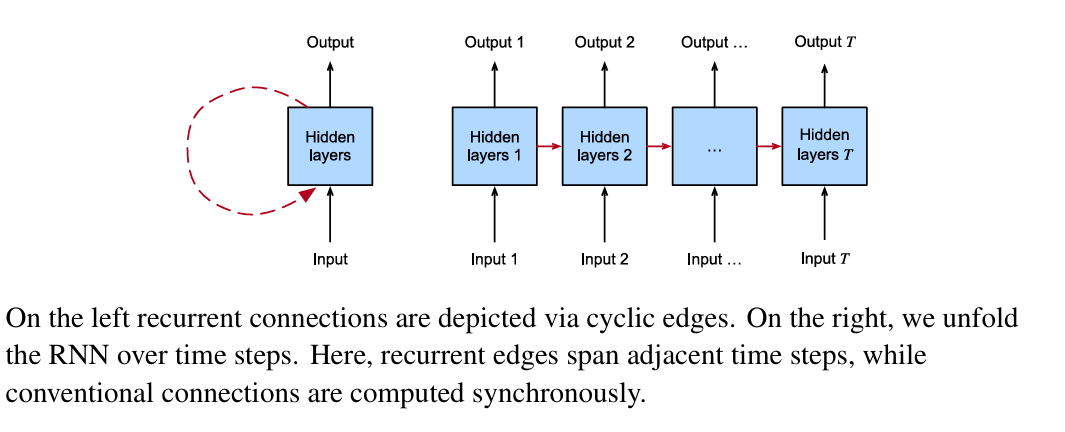


---

## 1. The Core Shift: From Static Vectors to Ordered Sequences

In traditional machine learning (e.g., standard feedforward networks or CNNs), an individual data point is treated as a single static feature vector:


$$\mathbf{x} \in \mathbb{R}^d$$

When dealing with sequences, our input transforms into an **ordered list of feature vectors**:


$$\mathbf{x}_1, \dots, \mathbf{x}_T$$


where each $\mathbf{x}_t \in \mathbb{R}^d$ corresponds to a specific time step $t \in \mathbb{Z}^+$ over a sequence of length $T$.

### Why This Matters: Relaxing the i.i.d. Assumption

Most classical statistical learning relies heavily on the **i.i.d. assumption** (Independent and Identically Distributed), meaning individual samples are drawn independently from an underlying distribution $P(X)$.

In sequence modeling:

* **Across sequences:** We still assume that entire sequences (e.g., distinct documents, separate patient hospital stays) are sampled independently from one another.
* **Within a sequence:** We explicitly **drop independence**. The elements $\mathbf{x}_t$ and $\mathbf{x}_{t+1}$ are deeply correlated. A word later in a sentence depends on syntax and semantics established earlier; a patient's medical treatment on Day 10 is conditioned on their clinical trajectory over the previous 9 days.
* **Non-stationarity:** We do not even require stationarity. The underlying data distribution can evolve over time—such as a patient's health deteriorating or improving, or language drifting across different sections of a long document.

---

## 2. Taxonomy of Sequence Learning Tasks

Machine learning tasks involving sequences generally fall into four structural categories based on the nature of the input and the target:

| Task Type | Input Structure | Target Structure | Real-World Example |
| --- | --- | --- | --- |
| **Unsupervised Density Modeling** | Sequential ($\mathbf{x}_1, \dots, \mathbf{x}_T$) | None (Estimating $p$) | Language modeling, climate stream analysis |
| **Classification / Regression** | Sequential ($\mathbf{x}_1, \dots, \mathbf{x}_T$) | Fixed Target ($y$) | Sentiment analysis (movie review $\rightarrow$ positive/negative) |
| **Generation / Captioning** | Fixed Input ($x$) | Sequential ($y_1, \dots, y_T$) | Image captioning |
| **Sequence-to-Sequence (Aligned)** | Sequential ($\mathbf{x}_1, \dots, \mathbf{x}_T$) | Sequential ($y_1, \dots, y_T$) | Part-of-speech (POS) tagging |
| **Sequence-to-Sequence (Unaligned)** | Sequential ($\mathbf{x}_1, \dots, \mathbf{x}_T$) | Sequential ($y_1, \dots, y_T$) | Machine translation, video-to-text |

---

## 3. The Foundation: Unsupervised Density Modeling
Given a collection of sequences, our goal is to estimate the joint probability mass function over the entire sequence:


$$p(\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_T)$$

Directly estimating this joint distribution is computationally intractable because the number of possible sequences grows exponentially with length $T$. This necessitates clever factorization strategies (like the chain rule of probability and Markov assumptions) which form the mathematical backbone of Autoregressive Models, Hidden Markov Models, and Recurrent Neural Networks (RNNs).

In [1]:
%matplotlib inline
import torch
from torch import nn
from d2l import torch as d2l

### **Autoregressive Models**

## 1. The Core Concept: Autoregressive Models

An **autoregressive model** is a type of model that regresses a variable on its own lagged (previous) values.

* **The Setup:** Suppose a trader wants to predict the price of an index ($x_t$) at a future time step $t$, given only the historical sequence of prices up to that point $(x_{t-1}, \dots, x_1)$.


* **The Conditional Probability:** The object of interest is the conditional probability distribution:

$$P(x_t \mid x_{t-1}, \dots, x_1)$$





* **Target Statistics:** While predicting the full continuous distribution can be complex, models often focus on key statistics such as the **expected value** (conditional expectation) and **variance**:



$$\mathbb{E}[x_t \mid x_{t-1}, \dots, x_1]$$






---

## 2. The Fundamental Challenge of Variable-Length Inputs

Standard machine learning models (like traditional linear regression or basic feedforward neural networks) expect a **fixed-length input vector**. However, time-series data introduces a structural dilemma:

* As time $t$ increases, the number of historical inputs ($x_{t-1}, \dots, x_1$) grows linearly ($t-1$ inputs).


* This means each training example would have a different number of features, breaking standard model architectures.



To solve this dimensionality mismatch, the text outlines **two primary strategies**:

---

## 3. Two Strategies for Handling Historical Data

### Strategy 1: Fixed-Length Window (Truncation)

* **How it works:** Instead of looking back across the entire history of the sequence, we restrict our view to a fixed window of length $\tau$.


* **Inputs used:** Only the recent observations $(x_{t-1}, \dots, x_{t-\tau})$ for $t > \tau$.


* **Advantage:** The number of input arguments is always constant ($\tau$), making it directly compatible with standard linear models or feedforward neural networks.


* **Limitation:** It discards long-range historical context that occurred further back than $\tau$ steps.

### Strategy 2: Latent Autoregressive Models (State-Space / RNN Approach)

* **How it works:** Instead of keeping raw historical values, we maintain a **fixed-size summary or hidden state $h_t$** of the past observations.


* **The Update Mechanism:**
* The hidden state updates recursively: $h_t = g(h_{t-1}, x_{t-1})$.


* The prediction is made based on this hidden state: $\hat{x}_t = P(x_t \mid h_t)$.




* **Why "Latent"?** Because the hidden state $h_t$ is never directly observed in the raw data—it is learned and maintained internally by the model. This architecture forms the foundational blueprint for **Recurrent Neural Networks (RNNs)**, as illustrated in Fig. 9.1.2.

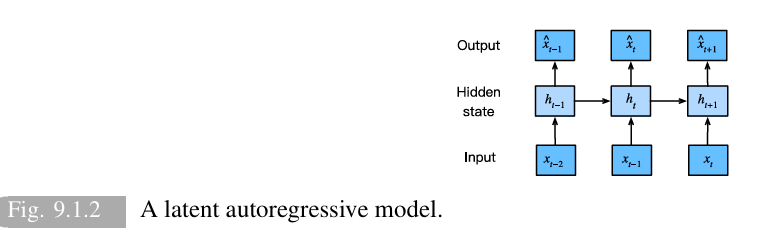



---

## 4. The Stationarity Assumption

When training these models on historical data (like sampling windows randomly from a 30-year stock chart), we make a crucial statistical assumption:

* **Time does not stand still**, and specific values of $x_t$ will change drastically over decades.


* However, we assume the **dynamics** governing how future observations are generated from past observations remain **stationary** (i.e., the underlying rules of the system do not change over time).


## 1. Sequence Models & Language Models

When working with discrete text tokens (such as words), estimating the joint probability of an entire sequence $P(x_1, \dots, x_T)$ is known as **sequence modeling**. When applied to natural language data, these are specifically called **language models**.

* **Capabilities:** Language models allow us to evaluate sentence likelihoods (e.g., comparing candidate outputs from machine translation or speech recognition systems), sample new sequences, and optimize for the most likely sequences.


* **Autoregressive Reduction:** Language modeling can be framed as an autoregressive problem by decomposing the joint sequence density into a product of conditional densities from left to right using the chain rule of probability:



$$P(x_1, \dots, x_T) = P(x_1) \prod_{t=2}^{T} P(x_t \mid x_{t-1}, \dots, x_1)$$





* **Discrete Signals:** Because words are discrete categories, the autoregressive model acts as a probabilistic classifier that outputs a full probability distribution over the vocabulary for the next word given the left-hand context.



---

## 2. Markov Models & Approximating Context

Because tracking infinite history is computationally intractable, we often condition only on a fixed window of the $\tau$ previous time steps ($x_{t-1}, \dots, x_{t-\tau}$) rather than the entire history ($x_{t-1}, \dots, x_1$).

* **The Markov Condition:** If throwing away history beyond the previous $\tau$ steps causes no loss in predictive power, the sequence satisfies the **Markov condition** (meaning the future is conditionally independent of the past, given the recent history).


* **Order Classifications:**
* **First-order Markov model ($\tau = 1$):** The probability depends *only* on the immediately preceding token:



$$P(x_1, \dots, x_T) = P(x_1) \prod_{t=2}^{T} P(x_t \mid x_{t-1})$$





* **$k$-th order Markov model ($\tau = k$):** The probability depends on the preceding $k$ steps.




* **Diminishing Returns of Context:** In real text documents, while we continue to gain contextual information as we look further back leftwards, those gains **diminish rapidly**. Consequently, even massive modern RNN and Transformer language models rarely utilize more than thousands of words of context. With discrete data, true Markov models estimate $P(x_t \mid x_{t-1})$ via relative frequency counts, allowing efficient sequence computation using dynamic programming.



---

## 3. The Order of Decoding

The text addresses why we typically factorize text sequences in a **left-to-right** direction rather than right-to-left or random orders:

1. **Cognitive Alignment:** Left-to-right matches how most languages are read and mirrors our natural human ability to anticipate upcoming words and complete sentences.


2. **Flexible Sequence Extension:** Factorizing in order makes it easy to extend probabilities to arbitrarily longer sequences. To expand a sequence from step $t$ to $t+1$, we simply multiply by the conditional probability of the new token given the prior ones:

$$P(x_{t+1}, \dots, x_1) = P(x_t, \dots, x_1) \cdot P(x_{t+1} \mid x_t, \dots, x_1)$$





3. **Causal Structure & Predictive Ease:** Data is often causally structured—future events cannot influence the past ($x_t$ can influence $x_{t+1}$, but not vice versa). This makes forward conditional prediction ($P(x_{t+1} \mid x_t)$) cleaner and more stable than reverse prediction.

In [16]:
# Training a linear model with synthetic data to understand how linear model can be used to predict time series

class Data(d2l.DataModule):
    def __init__(self, batch_size=16, T=1000, num_train=600, tau=4):
        super().__init__()
        self.save_hyperparameters()
        self.time = torch.arange(1, T + 1, dtype=torch.float32)
        self.x = torch.sin(0.01 * self.time) + torch.randn(T) * 0.2

    def get_dataloader(self, train):
        features = [self.x[i : self.T-self.tau+i] for i in range(self.tau)]
        self.features = torch.stack(features, 1)
        self.labels = self.x[self.tau:].reshape((-1, 1))
        i = slice(0, self.num_train) if train else slice(self.num_train, None)
        return self.get_tensorloader([self.features, self.labels], train, i)


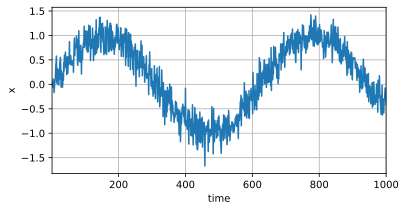

In [17]:
data = Data()
d2l.plot(data.time, data.x, 'time', 'x', xlim=[1, 1000], figsize=(6, 3))

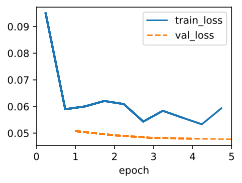

In [18]:
model = d2l.LinearRegression(lr=0.01)
trainer = d2l.Trainer(max_epochs=5)
trainer.fit(model, data)


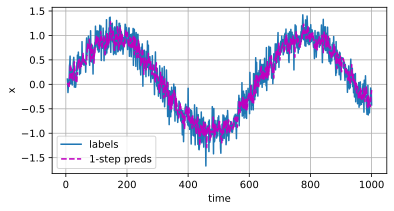

In [19]:
onestep_preds = model(data.features).detach().numpy()
d2l.plot(data.time[data.tau:], [data.labels, onestep_preds], 'time', 'x',
legend=['labels', '1-step preds'], figsize=(6, 3))


We can see that out model performs well on one-step ahead prediction.

But what if we only observed data till time step 604 (num_train + tau) and wished to predict several steps in future say at t=609?
We cannot directly compute value at time step 609 as we don't have values for **time step 605 to 608**. 

We can address this issue by predicting value at **time step 605**, then at **time step 606**, then at **time step 607**, and so on to predict value at **time step 609**.

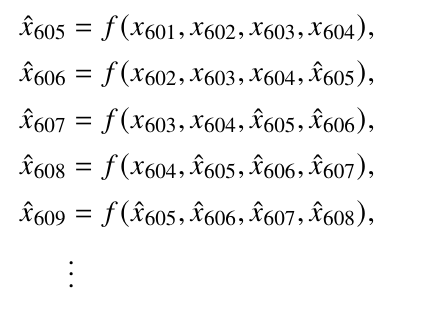

For observed sequence $X_1, X_2, \dots, X_{T}$, its  predicted output $X_{t+k}$ at time step 

We can see that out model performs well on one-step ahead prediction.

But what if we only observed data till time step 604 (num_train + tau) and wished to predict several steps in future say at t=609?
We cannot directly compute value at time step 609 as we don't have values for **time step 605 to 608**. 

We can address this issue by predicting value at **time step 605**, then at **time step 606**, then at **time step 607**, and so on to predict value at **time step 609**.

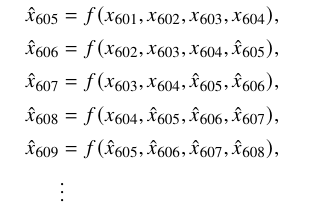

For observed sequence $X_1, X_2, \dots, X_{T}$, its  predicted output $X_{t+k}$ at time step ***t+k*** is called **k-step ahead prediction**.

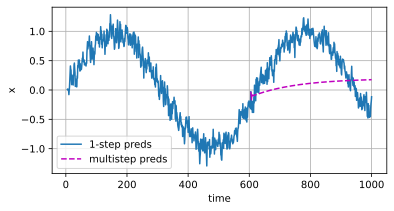

In [20]:
# Perform multi-step prediction
multistep_preds = torch.zeros(data.T)
multistep_preds[:] = data.x

for i in range(data.num_train + data.tau, data.T):
    multistep_preds[i] = model(
        multistep_preds[i - data.tau:i].reshape((1, -1))
    )

multistep_preds = multistep_preds.detach().numpy()

# Plot the predictions
d2l.plot(
    [data.time[data.tau:], data.time[data.num_train + data.tau:]],
    [onestep_preds, multistep_preds[data.num_train + data.tau:]],
    'time',
    'x',
    legend=['1-step preds', 'multistep preds'],
    figsize=(6, 3)
)

We can see that out models performs poorly on multi-step ahead prediction. This is because errors are accumulated as we move forward in time due to which predictions diverge significantly from actual values.

Let’s take a closer look at the difficulties in 𝑘-step-ahead predictions by computing predictions on the entire sequence for **𝑘 = 1,4,16,64**.

In [21]:
def k_step_pred(k):
    features = []

    for i in range(data.tau):
        features.append(
            data.x[i : i + data.T - data.tau - k + 1]
        )

    # The (i + tau)-th element stores the (i + 1)-step-ahead predictions
    for i in range(k):
        preds = model(
            torch.stack(features[i : i + data.tau], 1)
        )
        features.append(preds.reshape(-1))

    return features[data.tau:]

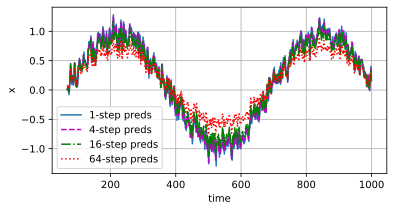

In [22]:
steps = (1, 4, 16, 64)

preds = k_step_pred(steps[-1])

d2l.plot(
    data.time[data.tau + steps[-1] - 1:],
    [preds[k - 1].detach().numpy() for k in steps],
    'time',
    'x',
    legend=[f'{k}-step preds' for k in steps],
    figsize=(6, 3)
)

### The quality of predictions degrades as the we try to predict further in the future